load info

In [1]:
# copy from Starloc.ipynb step 1, for basic info loading
from utils.calibration import CalibrationSignal
import os
from matplotlib import pyplot as plt
import scipy.io as sio
import numpy as np
# iq0_path ='/home/ishani/LeoPNT/USRP_data/2_5/utctime_5Feb2024_23:58:08_freq_11_325G_bw_2.0M_ts_1707177488.0938272_inrx0.dat'
iq0_path ='/home/ishani/LeoPNT/USRP_data/2_20/utctime_20Feb2024_23_19_57_freq_11_325G_bw_2.0M_ts_1708471197.0514207_inrx0.dat'
iq1_path = iq0_path.replace('inrx0', 'inrx1')
iq2_path = iq0_path.replace('inrx0', 'inrx2')
# date = iq0_path.split('_')[-10]+'_'+iq0_path.split('_')[-9].replace(":","-")
date = iq0_path.split('_')[-12]+'_'+iq0_path.split('_')[-11]+'_'+iq0_path.split('_')[-10]
start_time = float(iq0_path.split('_')[-2])
fc = 11.325e9
tx_freq = 11.3251e9
sample_rate = 2e6

simulation based

In [2]:
# first cheat by using the gt location to get the random phase offset (mean value for all satellites)
from sat_id import aoa_sim_1_sat
import random
t_sim_list = sio.loadmat(date+'/output_doppler.mat')['t_list']
dopp_track_dict = sio.loadmat(date+'/phase_comp.mat')['dopp_track_dict']
id_dict = sio.loadmat(date+'/phase_comp.mat')['id_dict']
sat_dopp_struct = sio.loadmat(date+'/phase_comp.mat')['sat_dopp_dict']
sat_num = len(dopp_track_dict[0, :])

# tracked tones' phase diff
az_gt_list, el_gt_list, t_sim_arr, del_phi_01_gt_list, del_phi_12_gt_list, del_phi_01_list, del_phi_12_list, range_gt_list = [], [], [], [], [], [], [], []
# set d_10, d_12 to be uniform distribution around 13.25e-2
d = 13.25e-2 # meter
d_bound = .1e-2 # meter
ang_bound = 3 # degree
d_10 = d + random.uniform(-d_bound, d_bound)
d_12 = d + random.uniform(-d_bound, d_bound)
ang_10_1 = np.deg2rad(random.uniform(-ang_bound, ang_bound))
# ang_10_1 = np.deg2rad(0)
ang_10_2 = np.deg2rad(random.uniform(-ang_bound, ang_bound))
ang_12_1 = np.deg2rad(random.uniform(-ang_bound, ang_bound))
ang_12_2 = np.deg2rad(random.uniform(-ang_bound, ang_bound))

lam = 3e8/fc
loc_1_gt = np.array([0,0,0])   # suppose rx1 is at the origin
loc_0_gt = d_10 * np.array([-np.cos(ang_10_2)*np.sin(ang_10_1), -np.cos(ang_10_2)*np.cos(ang_10_1), -np.sin(ang_10_2)])
loc_2_gt = d_12 * np.array([np.cos(ang_12_2)*np.cos(ang_12_1), -np.cos(ang_12_2)*np.sin(ang_12_1), np.sin(ang_12_2)])
loc_1, loc_0, loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])
for sat_idx in range(sat_num):
    # time for tracked tones
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0]
    t_sat_start, t_sat_end = t_repeat[0].real, t_repeat[-1].real

    t_sim, az_gt, el_gt, range_gt = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1)
    t_sim += t_sat_start
    az_gt = np.radians(az_gt)
    el_gt = np.radians(el_gt)
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                         range_gt * np.cos(el_gt) * np.cos(az_gt),
                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin


    range_1_gt = np.linalg.norm(loc_sat-loc_1_gt, axis=1)
    range_0_gt = np.linalg.norm(loc_sat-loc_0_gt, axis=1)
    range_2_gt = np.linalg.norm(loc_sat-loc_2_gt, axis=1)
    del_phi_01_gt = -(range_0_gt-range_1_gt)/lam*2*np.pi
    del_phi_12_gt = -(range_1_gt-range_2_gt)/lam*2*np.pi

    range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
    range_0 = np.linalg.norm(loc_sat-loc_0, axis=1)
    range_2 = np.linalg.norm(loc_sat-loc_2, axis=1)
    del_phi_01 = -(range_0-range_1)/lam*2*np.pi
    del_phi_12 = -(range_1-range_2)/lam*2*np.pi

    del_phi_01_gt_list.append(del_phi_01_gt)
    del_phi_12_gt_list.append(del_phi_12_gt)
    del_phi_01_list.append(del_phi_01)
    del_phi_12_list.append(del_phi_12)
    az_gt_list.append(az_gt)
    el_gt_list.append(el_gt)
    range_gt_list.append(range_gt)
    t_sim_arr.append(t_sim)

real world data

In [2]:
from sat_id import aoa_sim_1_sat, aoa_sim_1_sat_eph
t_sim_list = sio.loadmat(date+'/output_doppler.mat')['t_list']
dopp_track_dict = sio.loadmat(date+'/phase_comp.mat')['dopp_track_dict']
id_dict = sio.loadmat(date+'/phase_comp.mat')['id_dict']
sat_dopp_struct = sio.loadmat(date+'/phase_comp.mat')['sat_dopp_dict']
ref_sig_idx = sio.loadmat(date+'/info.mat')['ref_sig_idx']
phase_offset_01 = sio.loadmat(date+'/info.mat')['phase_offset_01'][0]
phase_offset_21 = sio.loadmat(date+'/info.mat')['phase_offset_21'][0]
sat_num = len(dopp_track_dict[0, :])

# tracked tones' phase diff
del_phi_01_gt_list, del_phi_12_gt_list, t_sim_arr, az_gt_list, el_gt_list, range_gt_list, del_phi_01_list, del_phi_12_list = [], [], [], [], [], [], [], []
d, lam = 13.25e-2, 3e8/fc
loc_1, loc_0, loc_2 = np.array([0,0,0]), np.array([0,-d,0]), np.array([d,0,0])
gap_01_arr, gap_12_arr = np.array([]), np.array([]) 
for sat_idx in range(sat_num):
    # time for tracked tones
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    t_sat_start, t_sat_end = t_repeat[0].real, t_repeat[-1].real
    # time for simulated doppler
    t_sim = t_sim_list[(t_sim_list > t_sat_start-1) & (t_sim_list < t_sat_end+1)]
    az_gt = sat_dopp_struct[id_dict[0,sat_idx][0]][0,0][1,:]
    el_gt = sat_dopp_struct[id_dict[0,sat_idx][0]][0,0][2,:]
    el_gt = np.radians(el_gt[((t_sim_list > t_sat_start-1) & (t_sim_list < t_sat_end+1))[0]])
    az_gt = np.radians(az_gt[((t_sim_list > t_sat_start-1) & (t_sim_list < t_sat_end+1))[0]])

    t_sim, az_gt, el_gt, range_gt = aoa_sim_1_sat(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .01)
    t_sim += t_sat_start
    az_gt = np.radians(az_gt)
    el_gt = np.radians(el_gt)
    loc_u = np.column_stack((np.cos(el_gt) * np.sin(az_gt),
                         np.cos(el_gt) * np.cos(az_gt),
                         np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

    # subtract the ref sig's phase
    ref_sig_ii = np.argmin(np.abs(ref_sig_idx[:, 0]/sample_rate-t_sat_start))
    phase_offset_01_ = phase_offset_01[ref_sig_ii]
    phase_offset_12_ = -phase_offset_21[ref_sig_ii]

    del_phi_repeat_01 = np.unwrap(np.angle(dopp_track[:, 2])-np.angle(dopp_track[:, 3])) - phase_offset_01_
    del_phi_repeat_12 = np.unwrap(np.angle(dopp_track[:, 3])-np.angle(dopp_track[:, 4])) - phase_offset_12_

    range_1 = np.linalg.norm(1e7*loc_u-loc_1, axis=1)
    range_0 = np.linalg.norm(1e7*loc_u-loc_0, axis=1)
    range_2 = np.linalg.norm(1e7*loc_u-loc_2, axis=1)
    del_phi_01_gt = -(range_0-range_1)/lam*2*np.pi
    del_phi_12_gt = -(range_1-range_2)/lam*2*np.pi

    # calculate gap
    coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 2)
    coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 2)
    gap_01 = np.mean(del_phi_01_gt-np.polyval(coeff_01, t_sim)).real
    gap_12 = np.mean(del_phi_12_gt-np.polyval(coeff_12, t_sim)).real

    while np.abs(gap_01-np.mean(gap_01_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_01-np.mean(gap_01_arr))
        gap_01 -= tmp
        del_phi_repeat_01 += tmp
    while np.abs(gap_12-np.mean(gap_12_arr)) > 1.5*np.pi:
        tmp = 2*np.pi*np.sign(gap_12-np.mean(gap_12_arr))
        gap_12 -= tmp
        del_phi_repeat_12 += tmp

    # fit the discrete data points with polynomial (second order)
    coeff_01 = np.polyfit(t_repeat, del_phi_repeat_01, 3)
    coeff_12 = np.polyfit(t_repeat, del_phi_repeat_12, 3)
    del_phi_01_gt_list.append(np.polyval(coeff_01, t_sim))
    del_phi_12_gt_list.append(np.polyval(coeff_12, t_sim))
    del_phi_01_list.append(del_phi_01_gt)
    del_phi_12_list.append(del_phi_12_gt)
    
    gap_01_arr = np.append(gap_01_arr, gap_01)
    gap_12_arr = np.append(gap_12_arr, gap_12)
    az_gt_list.append(az_gt)
    el_gt_list.append(el_gt)
    range_gt_list.append(range_gt)
    t_sim_arr.append(t_sim)

/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/numpy/core/fromnumeric.py:3504: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/jidazhang/anaconda3/envs/starloc/lib/python3.9/site-packages/numpy/core/_methods.py:129: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


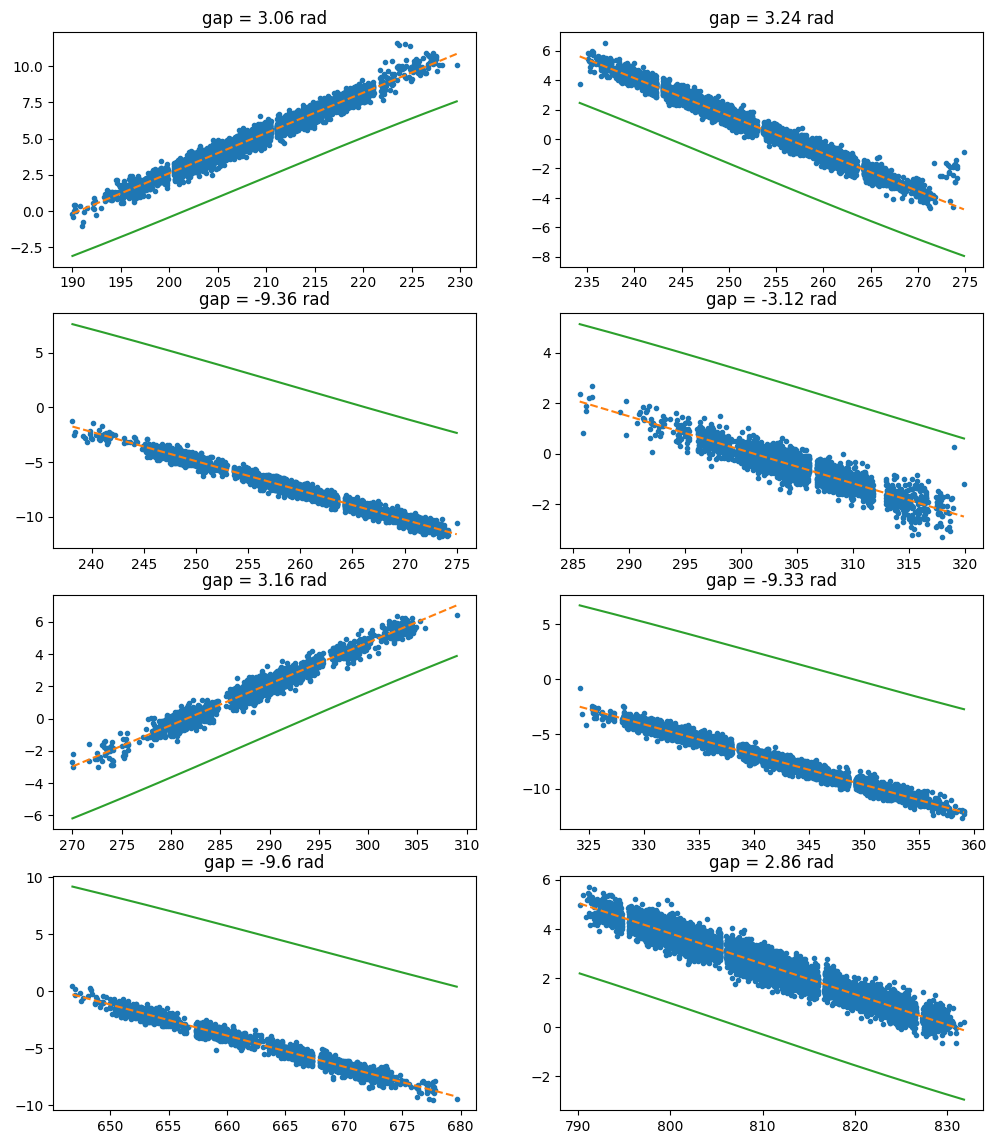

3.1122789950275402


In [16]:
# big figure
plt.figure(figsize=(12, 14))
gap_arr = np.array([])
for sat_idx in range(8):
    plt.subplot(4, 2, sat_idx+1)
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0].real
    t_sat_start, t_sat_end = t_repeat[0], t_repeat[-1]
    del_phi_01_repeat = np.unwrap(np.angle(dopp_track[:, 2])-np.angle(dopp_track[:, 3]))
    coeff_01 = np.polyfit(t_repeat, del_phi_01_repeat, 1)
    plt.plot(t_repeat, del_phi_01_repeat, '.')
    plt.plot(t_repeat, np.polyval(coeff_01, t_repeat), '--')
    plt.plot(t_sim_arr[sat_idx], del_phi_01_list[sat_idx])
    gap = np.mean(-del_phi_01_list[sat_idx] + np.polyval(coeff_01, t_sim_arr[sat_idx]))
    plt.title('gap = '+str(round(gap, 2))+' rad')
    gap_arr = np.append(gap_arr, gap)
plt.show()
print(np.mean(np.mod(gap_arr, 2*np.pi)))
    # print(np.std(del_phi_01_repeat-np.polyval(coeff_01, t_repeat)))
    # print(np.std(del_phi_01_list[sat_idx]-np.polyval(coeff_01, t_sim_arr[sat_idx])))
    # print(np.mod(np.mean(del_phi_01_list[sat_idx]-np.polyval(coeff_01, t_sim_arr[sat_idx])), 2*np.pi))

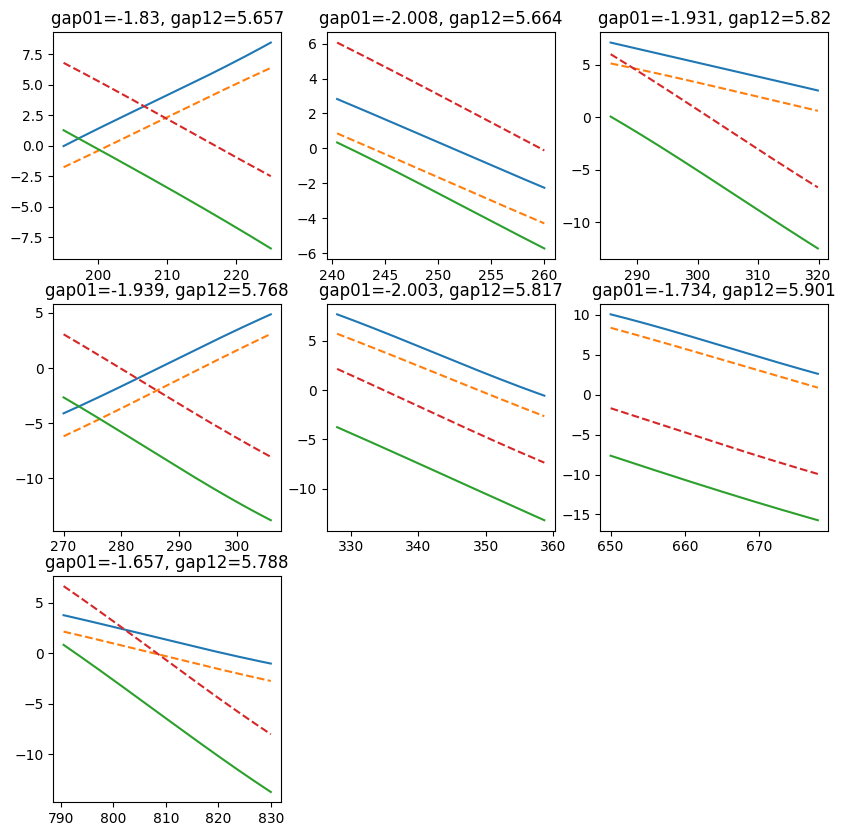

In [30]:
# plot a large fig
# plot for phase diff
plt.figure(figsize=(10, 10))
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]
    plt.subplot(3, 3, sat_idx+1)
    plt.plot(t_sim, del_phi_01_gt_list[sat_idx], label='gt')
    plt.plot(t_sim, del_phi_01_list[sat_idx], '--')

    plt.plot(t_sim, del_phi_12_gt_list[sat_idx], label='gt')
    plt.plot(t_sim, del_phi_12_list[sat_idx], '--')
    plt.title('gap01='+str(round(np.mean(del_phi_01_list[sat_idx]-del_phi_01_gt_list[sat_idx]),3))+', gap12='+str(round(np.mean(del_phi_12_list[sat_idx]-del_phi_12_gt_list[sat_idx]),3)))
plt.show()
# plot for derivative of phase diff
# plt.figure(figsize=(8, 8))
# for sat_idx in range(sat_num):
#     dopp_track = dopp_track_dict[0, sat_idx]
#     t_sim = t_sim_arr[sat_idx]
#     plt.subplot(3, 3, sat_idx+1)
#     plt.plot(t_sim[0:-1], np.diff(del_phi_01_gt_list[sat_idx]), label='gt')
#     plt.plot(t_sim[0:-1], np.diff(del_phi_01_list[sat_idx]), '--')

#     plt.plot(t_sim[0:-1], np.diff(del_phi_12_gt_list[sat_idx]), label='gt')
#     plt.plot(t_sim[0:-1], np.diff(del_phi_12_list[sat_idx]), '--')
# plt.show()

In [35]:
# do grid search
from tqdm import tqdm
# ang_10_1_grid, ang_10_2_grid = np.array([np.rad2deg(ang_10_1)]), np.linspace(-ang_bound, ang_bound, 500)
ang_bound = 3 # degree
ang_10_1_grid, ang_10_2_grid = np.linspace(-ang_bound, ang_bound, 1000), np.linspace(-ang_bound, ang_bound, 1000)
ang_12_1_grid, ang_12_2_grid = np.linspace(-ang_bound, ang_bound, 1000), np.linspace(-ang_bound, ang_bound, 1000)

loc_1 = np.array([0,0,0])   # suppose rx1 is at the origin
num_sat_for_training = 3

print('start grid search for ang_10_1, ang_10_2')
err_min_10 = np.inf
for ang_10_1_search in tqdm(ang_10_1_grid):
    ang_10_1_search = np.deg2rad(ang_10_1_search)
    for ang_10_2_search in ang_10_2_grid:
        err_arr = np.array([])
        ang_10_2_search = np.deg2rad(ang_10_2_search)
        loc_0 = d * np.array([-np.cos(ang_10_2_search)*np.sin(ang_10_1_search), -np.cos(ang_10_2_search)*np.cos(ang_10_1_search), -np.sin(ang_10_2_search)])

        for sat_idx in range(num_sat_for_training):
            az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
            loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                         range_gt * np.cos(el_gt) * np.cos(az_gt),
                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

            range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
            range_0 = np.linalg.norm(loc_sat-loc_0, axis=1)
            del_phi_01 = -(range_0-range_1)/lam*2*np.pi

            # different kinds of loss funcs            
            err_arr = np.append(err_arr, np.abs(del_phi_01-del_phi_01_gt_list[sat_idx]))
            # err_arr = np.append(err_arr, np.abs(np.diff(del_phi_01)-np.diff(del_phi_01_gt_list[sat_idx])))
        # err = np.sum(err_arr)
        err = np.var(err_arr)
        if err < err_min_10:
            err_min_10 = err
            ang_min_10 = np.array([ang_10_1_search, ang_10_2_search])

print('start grid search for ang_12_1, ang_12_2')
err_min_12 = np.inf
for ang_12_1_search in tqdm(ang_12_1_grid):
    ang_12_1_search = np.deg2rad(ang_12_1_search)
    for ang_12_2_search in ang_12_2_grid:
        err_arr = np.array([])
        ang_12_2_search = np.deg2rad(ang_12_2_search)
        loc_2 = d * np.array([np.cos(ang_12_2_search)*np.cos(ang_12_1_search), -np.cos(ang_12_2_search)*np.sin(ang_12_1_search), np.sin(ang_12_2_search)])
        for sat_idx in range(num_sat_for_training):
                        
            az_gt, el_gt, range_gt = az_gt_list[sat_idx], el_gt_list[sat_idx], range_gt_list[sat_idx]
            loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                         range_gt * np.cos(el_gt) * np.cos(az_gt),
                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

            range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
            range_2 = np.linalg.norm(loc_sat-loc_2, axis=1)
            del_phi_12 = -(range_1-range_2)/lam*2*np.pi
            
            err_arr = np.append(err_arr, np.abs(del_phi_12-del_phi_12_gt_list[sat_idx]))
            # err_arr = np.append(err_arr, np.abs(np.diff(del_phi_12)-np.diff(del_phi_12_gt_list[sat_idx])))
        # err = np.sum(err_arr)
        err = np.var(err_arr)
        if err < err_min_12:
            err_min_12 = err
            ang_min_12 = np.array([ang_12_1_search, ang_12_2_search])


start grid search for ang_10_1, ang_10_2


100%|██████████| 1000/1000 [01:28<00:00, 11.30it/s]


start grid search for ang_12_1, ang_12_2


100%|██████████| 1000/1000 [01:28<00:00, 11.31it/s]


In [36]:
print(np.rad2deg(ang_min_10))
print(np.rad2deg(ang_min_12))
# print(np.rad2deg(ang_10_1))
# print(np.rad2deg(ang_10_2))
# print(err_min_12)

[-0.32732733  3.        ]
[ 1.48648649 -1.57057057]


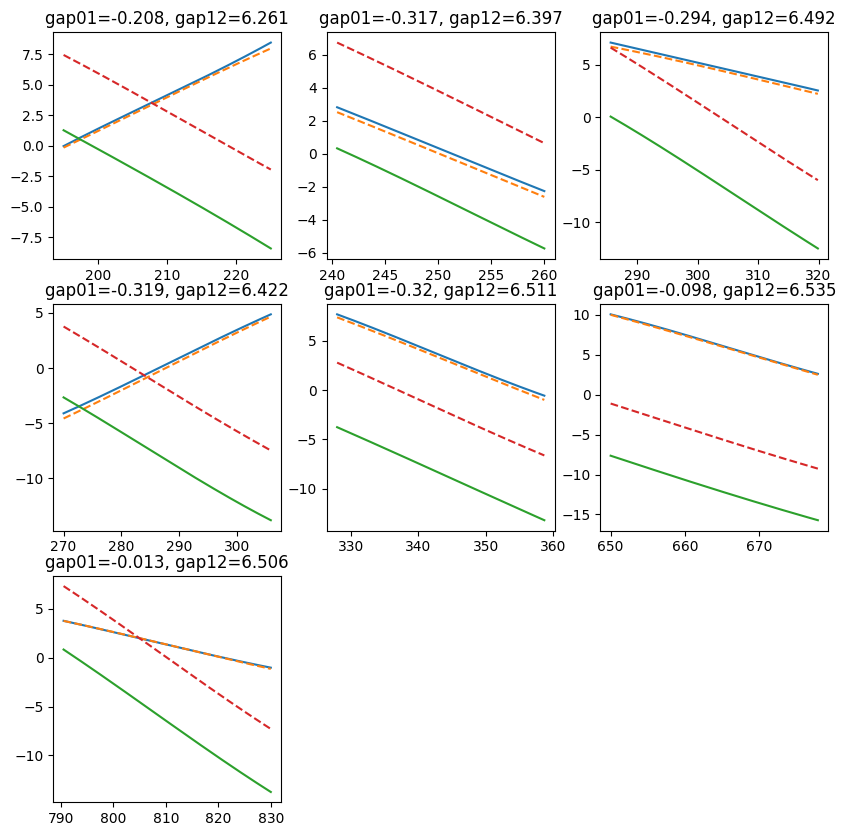

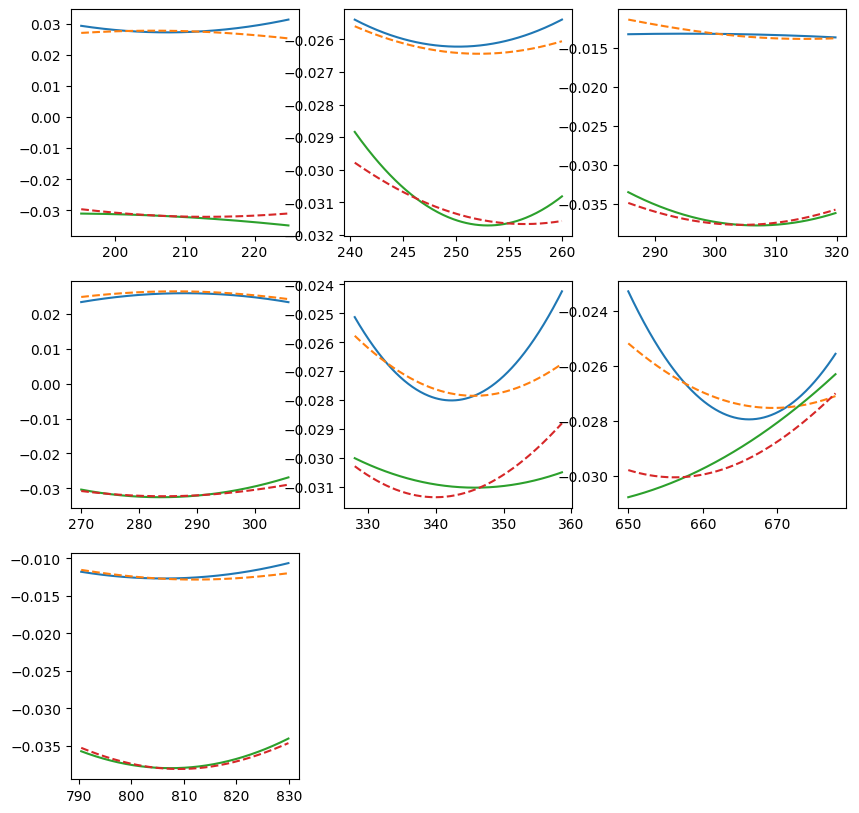

In [34]:
loc_1 = np.array([0,0,0])   # suppose rx1 is at the origin
ang_10_1_opt, ang_10_2_opt = ang_min_10
ang_12_1_opt, ang_12_2_opt = ang_min_12
loc_0 = d * np.array([-np.cos(ang_10_2_opt)*np.sin(ang_10_1_opt), -np.cos(ang_10_2_opt)*np.cos(ang_10_1_opt), -np.sin(ang_10_2_opt)])
loc_2 = d * np.array([np.cos(ang_12_2_opt)*np.cos(ang_12_1_opt), -np.cos(ang_12_2_opt)*np.sin(ang_12_1_opt), np.sin(ang_12_2_opt)])
del_phi_01_list, del_phi_12_list = [], []
for sat_idx in range(sat_num):
    # time for tracked tones
    dopp_track = dopp_track_dict[0, sat_idx]
    t_repeat = dopp_track[:, 0]
    t_sat_start, t_sat_end = t_repeat[0].real, t_repeat[-1].real

    t_sim, az_gt, el_gt, range_gt = aoa_sim_1_sat_eph(date, date+'/Starlink.tle', id_dict[0,sat_idx][0], start_time+t_sat_start, start_time+t_sat_end, .1)
    t_sim += t_sat_start
    az_gt = np.radians(az_gt)
    el_gt = np.radians(el_gt)
    loc_sat = np.column_stack((range_gt * np.cos(el_gt) * np.sin(az_gt),
                         range_gt * np.cos(el_gt) * np.cos(az_gt),
                         range_gt * np.sin(el_gt)))    # the unit vector pointing to the sat from the origin

    range_1 = np.linalg.norm(loc_sat-loc_1, axis=1)
    range_0 = np.linalg.norm(loc_sat-loc_0, axis=1)
    range_2 = np.linalg.norm(loc_sat-loc_2, axis=1)
    del_phi_01 = -(range_0-range_1)/lam*2*np.pi
    del_phi_12 = -(range_1-range_2)/lam*2*np.pi
    del_phi_01_list.append(del_phi_01)
    del_phi_12_list.append(del_phi_12)

# plot a large fig
# plot for phase diff
plt.figure(figsize=(10, 10))
# plt.title('d_10='+str(round(d_10,3))+', d_12='+str(round(d_12,3)))
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]
    plt.subplot(3, 3, sat_idx+1)
    plt.plot(t_sim, del_phi_01_gt_list[sat_idx], label='gt')
    plt.plot(t_sim, del_phi_01_list[sat_idx], '--')

    plt.plot(t_sim, del_phi_12_gt_list[sat_idx], label='gt')
    plt.plot(t_sim, del_phi_12_list[sat_idx], '--')
    plt.title('gap01='+str(round(np.mean(del_phi_01_list[sat_idx]-del_phi_01_gt_list[sat_idx]),3))+', gap12='+str(round(np.mean(del_phi_12_list[sat_idx]-del_phi_12_gt_list[sat_idx]),3)))
plt.show()
# plot for derivative of phase diff
plt.figure(figsize=(10, 10))
for sat_idx in range(sat_num):
    dopp_track = dopp_track_dict[0, sat_idx]
    t_sim = t_sim_arr[sat_idx]
    plt.subplot(3, 3, sat_idx+1)
    plt.plot(t_sim[0:-1], np.diff(del_phi_01_gt_list[sat_idx]), label='gt')
    plt.plot(t_sim[0:-1], np.diff(del_phi_01_list[sat_idx]), '--')

    plt.plot(t_sim[0:-1], np.diff(del_phi_12_gt_list[sat_idx]), label='gt')
    plt.plot(t_sim[0:-1], np.diff(del_phi_12_list[sat_idx]), '--')
plt.show()

In [22]:
id_1, id_2 = 0, 1
az_1, el_1 = az_gt_list[id_1], el_gt_list[id_1]
az_2, el_2 = az_gt_list[id_2], el_gt_list[id_2]
t_1, t_2 = t_sim_arr[id_1], t_sim_arr[id_2]
min_dis = np.inf
for i in range(len(az_1)):
    for j in range(len(az_2)):
        dis = np.linalg.norm(np.array([az_1[i], el_1[i]])-np.array([az_2[j], el_2[j]]))
        if dis < min_dis:
            min_dis = dis
            i_min, j_min = i, j
t_1_min, t_2_min = t_1[i_min], t_2[j_min]

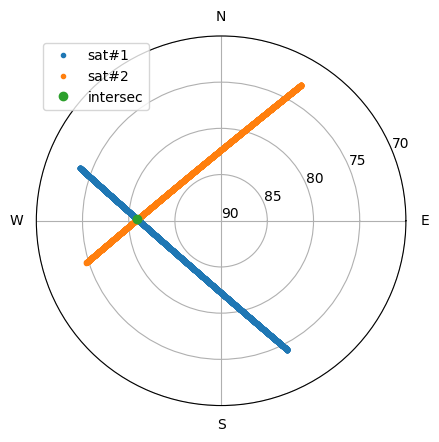

In [23]:
for sat_idx in [id_1, id_2]:
    plt.polar(np.deg2rad(90)-az_gt_list[sat_idx], 90-np.rad2deg(el_gt_list[sat_idx]), '.', label='sat#'+str(sat_idx+1))
plt.polar(np.deg2rad(90)-az_1[i_min], 90-np.rad2deg(el_1[i_min]), 'o', label='intersec')
# set the x ticks to be north, west, south, east
plt.xticks(np.deg2rad([0,90,180,270]), ['E', 'N', 'W', 'S'])
plt.yticks([0, 5, 10, 15, 20], ['90', '85', '80', '75', '70'])
plt.legend()
plt.show()

In [24]:
print(del_phi_01_gt_list[id_1][i_min])
print(del_phi_01_gt_list[id_2][j_min])
print(del_phi_01_gt_list[id_1][i_min] - del_phi_01_gt_list[id_2][j_min])
print(del_phi_12_gt_list[id_1][i_min])
print(del_phi_12_gt_list[id_2][j_min])
print(del_phi_12_gt_list[id_1][i_min] - del_phi_12_gt_list[id_2][j_min])

8.013404924318024
8.205881202232149
-0.1924762779141247
-6.914354824971717
-7.007481139085371
0.09312631411365402
